# Cost Optimization for AI Agents: Reducing API Calls
**Example context: a Data Analysis Agent**

## Concept 1: Bundling Queries

**Problem:** agents are chatty. They call a tool, wait, think, call another tool, wait again. Every "wait" is a full model round-trip that re-reads the entire context (system prompt, tool schemas, all prior messages).

**Fix**: Bundle queries

**Example:** "Compare last month's sales to the same month last year."

| Agent | Steps | Model round-trips |
|---|---|---|
| Naive | query last month -> wait -> query last year -> wait -> compare | 3 |
| Optimized | send both queries in one dispatch -> get both results -> compare | 2 |

The gap grows with the task: comparing 3 months against last year is 7 round-trips naive vs 2 optimized.

## What this notebook does
1. Models why round-trips are expensive (context re-read grows each turn).
2. Builds a SQLite sales database and tools for a LangChain/LangGraph agent.
3. Instruments the agent: model calls, tool calls, tokens, latency, cost.
4. Compares four strategies on the same questions:
   - **A. Naive:** one tool call per turn
   - **B. Parallel tool calls:** independent calls issued in the same turn
   - **C. Batch tool:** one tool that accepts a list of queries
5. Adds a hard cap on model calls as a safety net.

In [ ]:
# %pip install -q "langchain==1.3.6" "langchain-openai==1.2.2" "langgraph==1.2.4" pandas numpy matplotlib

In [2]:
import os, json, time, sqlite3, threading, getpass, datetime as dt
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from langchain.agents import create_agent
from langchain.tools import tool
from langchain_core.callbacks import BaseCallbackHandler
from langchain_openai import ChatOpenAI

In [4]:
# Check package version

import importlib.metadata

# List the distribution package names
packages = ["langchain", "langchain-community",  "langchain-text-splitters",
            "langchain-openai", "langgraph","matplotlib", "pandas" ]

for package in packages:
    try:
        version = importlib.metadata.version(package)
        print(f"{package} version: {version}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package} is not installed in this environment.")

langchain version: 1.3.6
langchain-community version: 0.4.2
langchain-text-splitters version: 1.1.2
langchain-openai version: 1.2.2
langgraph version: 1.2.4
matplotlib version: 3.11.2
pandas version: 3.0.5


In [3]:
# Get the key

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OPENAI_API_KEY: ")

MODEL = "gpt-4.1-mini"                       # any tool-calling chat model
PRICE = {"input": 0.40, "output": 1.60}      # USD per 1M tokens; placeholders, VERIFY
TODAY = dt.date.today()

OPENAI_API_KEY:  ········


## 1. (OPTIONAL) Why round-trips are expensive

Each model call re-sends the whole conversation. 

If every turn adds `g` tokens (tool call + tool result) on top of a base context `b`, then turn `k` costs
- `b + k*g` input tokens

Therefore, `n` turns cost
- **`total_input(n) = n*b + g*n*(n-1)/2`**

Cost is **quadratic in the number of turns**, so removing turns saves more than the turn count suggests. Numbers below are illustrative; the real measurement comes later.

In [6]:
def total_input(turns, base=1500, growth=350):
    return sum(base + k * growth for k in range(turns))


model_df = pd.DataFrame({"turns": range(2, 13)})
model_df["input_tokens"] = model_df["turns"].map(total_input)
model_df["x_vs_2_turns"] = (model_df["input_tokens"] / total_input(turns=2)).round(2)
model_df

,turns,input_tokens,x_vs_2_turns
0,2,3350,1.00
1,3,5550,1.66
2,4,8100,2.42
3,5,11000,3.28
4,6,14250,4.25
5,7,17850,5.33
6,8,21800,6.51
7,9,26100,7.79
8,10,30750,9.18
9,11,35750,10.67


## 2. Data and tools

A synthetic `sales` table (about 26 months of daily rows) in an in-memory SQLite database. Three tool designs, one per strategy:

- `run_sql(query)`: one query per call
- `run_sql_batch(queries)`: a list of queries per call
- `compare_periods(...)`: the comparison itself as a tool

All tools are read-only (`SELECT` only).

In [4]:
rng  = np.random.default_rng(42)
days = pd.date_range(TODAY - pd.Timedelta(days=800), TODAY - pd.Timedelta(days=1))
REGIONS = {"North": 1.0, "South": 0.8, "East": 1.2, "West": 0.9}
PRODUCTS = {"Laptop": 900, "Phone": 600, "Accessory": 60}

rows = []
for d in days:
    season = 1 + 0.2 * np.sin(2 * np.pi * d.dayofyear / 365)
    for region, rf in REGIONS.items():
        for product, base in PRODUCTS.items():
            rows.append((d.strftime("%Y-%m-%d"), region, product,
                         round(base * rf * season * rng.uniform(5, 15), 2)))

sales_df = pd.DataFrame(rows, columns=["order_date", "region", "product", "amount"])
sales_df.insert(0, "order_id", range(1, len(sales_df) + 1))

conn = sqlite3.connect(":memory:", check_same_thread=False)
sales_df.to_sql("sales", conn, index=False)
DB_LOCK = threading.Lock()

print(len(sales_df), "rows |", sales_df["order_date"].min(), "->", sales_df["order_date"].max())
sales_df.head(3)

9600 rows | 2024-08-10 -> 2026-10-18


,order_id,order_date,region,product,amount
0,1,2024-08-10,North,Laptop,9993.30
1,2,2024-08-10,North,Phone,4909.90
2,3,2024-08-10,North,Accessory,710.48


In [5]:
def _exec(query: str, max_rows: int = 50) -> dict:
    q = query.strip().rstrip(";")
    if not q.lower().startswith("select") or ";" in q:
        return {"error": "Only a single SELECT statement is allowed."}
    try:
        with DB_LOCK:
            cur = conn.execute(q)
            cols = [c[0] for c in cur.description]
            data = cur.fetchmany(max_rows)
        return {"columns": cols, "rows": data}
    except Exception as e:
        return {"error": str(e)}


@tool
def run_sql(query: str) -> str:
    """Run ONE read-only SQLite SELECT query against table sales(order_id, order_date TEXT 'YYYY-MM-DD', region, product, amount REAL). Returns rows as JSON."""
    return json.dumps(_exec(query))


@tool
def run_sql_batch(queries: list[str]) -> str:
    """Run MULTIPLE independent read-only SQLite SELECT queries in ONE call against table sales(order_id, order_date TEXT 'YYYY-MM-DD', region, product, amount REAL). Returns a JSON list of results in the same order as the queries."""
    return json.dumps([_exec(q) for q in queries])


@tool
def compare_periods(period_a_start: str, period_a_end: str, 
                    period_b_start: str, period_b_end: str
                   ) -> str:
    """
    Compare TOTAL sales between period A and period B (inclusive date ranges, YYYY-MM-DD). 
    Returns both totals and the percent change from A to B.
    """
    def total(s, e):
        r = _exec(f"SELECT ROUND(SUM(amount), 2) FROM sales WHERE order_date BETWEEN '{s}' AND '{e}'")
        return r["rows"][0][0] if "rows" in r else None
    
    a, b = total(period_a_start, period_a_end), total(period_b_start, period_b_end)
    pct = round((b - a) / a * 100, 2) if a and b is not None else None
    
    return json.dumps({"period_a_total": a, "period_b_total": b, "pct_change_a_to_b": pct})

In [6]:
# Ground truth from pandas, used to check the agents' answers.

sales_df["ym"] = sales_df["order_date"].str[:7]
monthly = sales_df.groupby("ym")["amount"].sum()


def last_n_months(n):
    cur, out = TODAY.replace(day=1), []
    for _ in range(n):
        cur = (cur - dt.timedelta(days=1)).replace(day=1)
        out.append(cur)
    return out


truth = pd.DataFrame([
    {"month": m.strftime("%Y-%m"),
     "this_year": round(monthly[m.strftime("%Y-%m")], 2),
     "year_before": round(monthly[f"{m.year - 1}-{m.month:02d}"], 2)}
    for m in last_n_months(3)
])


truth["pct_change"] = ((truth["this_year"] / truth["year_before"] - 1) * 100).round(2)

truth

,month,this_year,year_before,pct_change
0,2026-09,1496814.22,1426050.32,4.96
1,2026-08,1586401.77,1567798.35,1.19
2,2026-07,1764904.33,1805914.75,-2.27


## 3. Instrumentation

A callback handler counts every model call, tool call, and token. Passing it through `config["callbacks"]` captures every model round-trip inside the LangGraph agent loop.

In [8]:
class CallStats(BaseCallbackHandler):
    def __init__(self):
        self.llm_calls = 0
        self.tool_calls = 0
        self.in_tokens = 0
        self.out_tokens = 0
        self.per_call_in = []

    def on_llm_end(self, response, **kwargs):
        self.llm_calls += 1
        for gens in response.generations:
            for g in gens:
                um = getattr(getattr(g, "message", None), "usage_metadata", None)
                if um:
                    self.in_tokens += um["input_tokens"]
                    self.out_tokens += um["output_tokens"]
                    self.per_call_in.append(um["input_tokens"])

    def on_tool_start(self, serialized, input_str, **kwargs):
        self.tool_calls += 1


def run_agent(agent, question):
    stats = CallStats()
    t0 = time.time()
    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        config={"callbacks": [stats], "recursion_limit": 40},
    )
    return {
        "llm_calls": stats.llm_calls,
        "tool_calls": stats.tool_calls,
        "input_tokens": stats.in_tokens,
        "output_tokens": stats.out_tokens,
        "seconds": round(time.time() - t0, 1),
        "cost_usd": (stats.in_tokens * PRICE["input"] + stats.out_tokens * PRICE["output"]) / 1e6,
        "per_call_in": stats.per_call_in,
        "answer": out["messages"][-1].content,
        "messages": out["messages"],
    }


def show_trace(messages):
    for m in messages:
        if m.type == "human":
            print("HUMAN :", m.content[:90])
        elif m.type == "ai":
            names = [tc["name"] for tc in m.tool_calls]
            print(f"MODEL : {len(names)} tool call(s) {names}" if names else "MODEL : final answer")
        elif m.type == "tool":
            print(f"TOOL  : result ({len(m.content)} chars)")

## 4. Three strategies

| | Tools | Prompt | Parallel tool calls |
|---|---|---|---|
| **A. Naive** | `run_sql` | "one tool call, wait, then decide" | disabled |
| **B. Parallel tool calls** | `run_sql` | "issue independent calls in the same turn" | enabled |
| **C. Batch tool** | `run_sql_batch` | "send ALL queries in one call" | enabled |

- Strategy A disables `parallel_tool_calls` at the API level to reproduce the chatty behavior deterministically.
- Strategy B relies on the model emitting several tool calls in one assistant message; LangGraph's tool node then runs them together.

In [21]:
BASE = (
    "You are a data analysis agent. "
    "SQLite table: sales(order_id, order_date TEXT 'YYYY-MM-DD', region, product, amount REAL). "
    f"Today is {TODAY.isoformat()}. 'Last month' means the previous full calendar month. "
    "Answer concisely with both totals and the percent change."
)

STRATEGIES = {
    "A. Naive (1 call/turn)": dict(
        tools=[run_sql], parallel=False,
        prompt=BASE + " Work step by step: issue exactly ONE tool call, wait for its result, then decide the next step."),
    "B. Parallel tool calls": dict(
        tools=[run_sql], parallel=True,
        prompt=BASE + " When you need several independent queries, issue ALL of those tool calls in the same turn."),
    "C. Batch tool": dict(
        tools=[run_sql_batch], parallel=True,
        prompt=BASE + " Use run_sql_batch ONCE with ALL the queries you need, then answer."),
}


def build_agent(tools, prompt, parallel=True):
    llm = ChatOpenAI(
        model=MODEL,
        temperature=0,
        model_kwargs={} if parallel else {"parallel_tool_calls": False},
    )
    return create_agent(llm, tools, system_prompt=prompt)


AGENTS = { name: build_agent(cfg["tools"], cfg["prompt"], cfg["parallel"]) for name, cfg in STRATEGIES.items()}

list(AGENTS)

['A. Naive (1 call/turn)', 'B. Parallel tool calls', 'C. Batch tool']

## 5. Benchmark

Two questions:
- **Q1:** last month vs the same month last year (2 independent queries)
- **Q2:** each of the last 3 full months vs the same month a year earlier (6 independent queries)

Set `REPEATS` higher to average out model variance. This makes real API calls (a few cents in total).

In [22]:
# RUN: calls the API
# Took 30 seconds

QUESTIONS = {
    "Q1: last month vs last year": "Compare last month's total sales to the same month last year.",
    "Q2: last 3 months vs last year": "For each of the last 3 full months, compare total sales to the same month a year earlier.",
}
REPEATS = 1

records, last_run = [], {}
for qname, q in QUESTIONS.items():
    for sname, agent in AGENTS.items():
        for _ in range(REPEATS):
            r = run_agent(agent, q)
            last_run[(qname, sname)] = r
            records.append({"question": qname,
                            "strategy": sname,
                            **{k: r[k] for k in ["llm_calls", "tool_calls", "input_tokens", "output_tokens", "seconds", "cost_usd"]}
                           })

bench = pd.DataFrame(records).groupby(["question", "strategy"], sort=False).mean().reset_index()

baseline = bench[bench["strategy"].str.startswith("A.")].set_index("question")

bench["cost_vs_naive"] = bench.apply(lambda r: r["cost_usd"] / baseline.loc[r["question"], "cost_usd"], axis=1).round(2)
bench["time_vs_naive"] = bench.apply(lambda r: r["seconds"] / baseline.loc[r["question"], "seconds"], axis=1).round(2)
bench.round({"cost_usd": 5, "llm_calls": 1, "tool_calls": 1})

,question,strategy,llm_calls,tool_calls,input_tokens,output_tokens,seconds,cost_usd,cost_vs_naive,time_vs_naive
0,Q1: last month vs last year,A. Naive (1 call/turn),2.0,1.0,470.0,147.0,3.3,0.00042,1.00,1.00
1,Q1: last month vs last year,B. Parallel tool calls,2.0,2.0,491.0,159.0,2.6,0.00045,1.07,0.79
2,Q1: last month vs last year,C. Batch tool,2.0,1.0,492.0,133.0,2.8,0.00041,0.97,0.85
3,Q2: last 3 months vs last year,A. Naive (1 call/turn),9.0,8.0,11844.0,2291.0,19.5,0.00840,1.00,1.00
4,Q2: last 3 months vs last year,B. Parallel tool calls,2.0,2.0,615.0,281.0,2.9,0.00070,0.08,0.15
5,Q2: last 3 months vs last year,C. Batch tool,2.0,1.0,543.0,221.0,2.6,0.00057,0.07,0.13


### Trace: what each strategy did on Q1
Count the `MODEL` lines: each one is a full round-trip that re-reads the context.

In [11]:
for sname in STRATEGIES:
    print(f"--- {sname}")
    show_trace(last_run[("Q1: last month vs last year", sname)]["messages"])
    print()

--- A. Naive (1 call/turn)
HUMAN : Compare last month's total sales to the same month last year.
MODEL : 1 tool call(s) ['run_sql']
TOOL  : result (97 chars)
MODEL : final answer

--- B. Parallel tool calls
HUMAN : Compare last month's total sales to the same month last year.
MODEL : 2 tool call(s) ['run_sql', 'run_sql']
TOOL  : result (63 chars)
TOOL  : result (73 chars)
MODEL : final answer

--- C. Batch tool
HUMAN : Compare last month's total sales to the same month last year.
MODEL : 1 tool call(s) ['run_sql_batch']
TOOL  : result (140 chars)
MODEL : final answer



### Input tokens per model call (Q2)
Each additional round-trip re-reads a longer context. This is the quadratic effect from section 1, measured.

In [12]:
for sname in STRATEGIES:
    r = last_run[("Q2: last 3 months vs last year", sname)]
    print(f"{sname:28s} calls={r['llm_calls']}  input tokens per call: {r['per_call_in']}")

A. Naive (1 call/turn)       calls=6  input tokens per call: [175, 506, 805, 1086, 1367, 1733]
B. Parallel tool calls       calls=2  input tokens per call: [171, 444]
C. Batch tool                calls=2  input tokens per call: [185, 473]


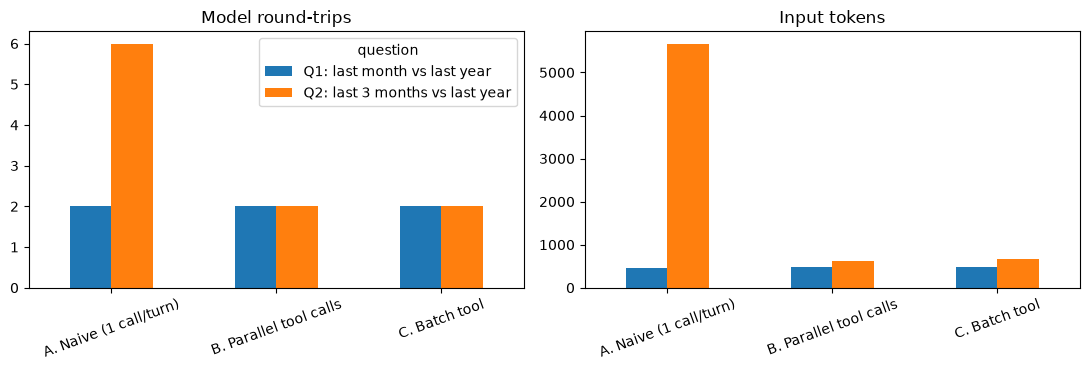

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bench.pivot(index="strategy", columns="question", values="llm_calls").loc[list(STRATEGIES)].plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Model round-trips"); axes[0].set_xlabel("")
bench.pivot(index="strategy", columns="question", values="input_tokens").loc[list(STRATEGIES)].plot.bar(ax=axes[1], rot=20, legend=False)
axes[1].set_title("Input tokens"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

### Correctness check
Fewer calls only matter if the answer stays right. Compare each Q1 answer with the pandas ground truth.

In [14]:
print("Ground truth (most recent month first):")
print(truth.head(1).to_string(index=False), "\n")
for sname in STRATEGIES:
    print(f"[{sname}]\n{last_run[('Q1: last month vs last year', sname)]['answer']}\n")

Ground truth (most recent month first):
  month  this_year  year_before  pct_change
2026-09 1496814.22   1426050.32        4.96 

[A. Naive (1 call/turn)]
Last month's total sales (September 2026) were 1,496,814.22. The total sales for the same month last year (September 2025) were 1,426,050.32. 

The percent change is ((1,496,814.22 - 1,426,050.32) / 1,426,050.32) * 100 = approximately 4.93% increase.

[B. Parallel tool calls]
Last month's total sales (September 2026) were 1,496,814.22. The total sales for the same month last year (September 2025) were 1,426,050.32. This represents an increase of approximately 4.93%.

[C. Batch tool]
Last month's total sales were $1,496,814.22. The total sales for the same month last year were $1,426,050.32. This represents an increase of approximately 4.93%.



---
## Concept 2: Tool output compaction

**Problem:** a data agent queries a table and gets back a massive JSON payload (100 rows x 50 columns). That entire payload enters the context window and is re-read on every subsequent turn.

**Fix:** don't put raw data in the context. Put a reference to it.

| Agent | What the query tool returns | What stays in context |
|---|---|---|
| Raw | all 100 rows x 50 columns as JSON | the full payload, re-read every turn |
| Reference | `ref` id, shape, column names, 3-row preview | a few hundred tokens |

The data stays in a Python-side store. Follow-up tools take the `ref` and compute on the data directly.

In [18]:
# A wide table: 100 rows x 50 columns
rng = np.random.default_rng(7)
metrics_df = pd.DataFrame(
    rng.normal(100, 25, size=(100, 49)).round(4),
    columns=[f"metric_{i:02d}" for i in range(1, 50)],
)

metrics_df.insert(0, "date", pd.date_range("2020-01-01", periods=100).strftime("%Y-%m-%d"))
metrics_df.to_sql("metrics", conn, index=False, if_exists="replace")

print("shape:", metrics_df.shape)
print("----------------------------------")

# Ground truth
truth_mean_07 = metrics_df["metric_07"].mean()
truth_max_23 = metrics_df["metric_23"].max()

print(f"Ground truth | mean(metric_07) = {truth_mean_07:.4f} | max(metric_23) = {truth_max_23:.4f}")

shape: (100, 50)
----------------------------------
Ground truth | mean(metric_07) = 98.9631 | max(metric_23) = 161.0115


### Tools
- `query_table(sql)`: both variants run the query and save the result in `DATA_STORE` under a `ref`. They differ only in what they return to the model.
- `column_stats(ref, column, stat)`: computes on the stored data. Shared by both agents, so the model never does arithmetic.

In [19]:
DATA_STORE = {}


def _store(df: pd.DataFrame) -> str:
    ref = f"df_{len(DATA_STORE) + 1}"
    DATA_STORE[ref] = df
    return ref


def _run_query(sql: str):
    q = sql.strip().rstrip(";")
    if not q.lower().startswith("select") or ";" in q:
        return None, "Only a single SELECT statement is allowed."
    try:
        with DB_LOCK:
            return pd.read_sql_query(q, conn), None
    except Exception as e:
        return None, str(e)


@tool("query_table")
def query_table_raw(sql: str) -> str:
    """Run ONE read-only SQLite SELECT query against table metrics(date TEXT, metric_01 ... metric_49 REAL). Returns the data and a ref id."""
    df, err = _run_query(sql)
    if err:
        return json.dumps({"error": err})
    return json.dumps({"ref": _store(df), "columns": list(df.columns), "rows": df.values.tolist()})


@tool("query_table")
def query_table_ref(sql: str) -> str:
    """Run ONE read-only SQLite SELECT query against table metrics(date TEXT, metric_01 ... metric_49 REAL). Returns a ref id, shape, columns, and a 3-row preview. Full data stays server-side."""
    df, err = _run_query(sql)
    if err:
        return json.dumps({"error": err})
    return json.dumps({
        "ref": _store(df),
        "shape": list(df.shape),
        "columns": list(df.columns),
        "preview": df.head(3).values.tolist(),
    })


@tool
def column_stats(ref: str, column: str, stat: str) -> str:
    """Compute a statistic on one column of a stored result. ref: id from query_table. stat: one of mean, max, min, sum."""
    df = DATA_STORE.get(ref)
    if df is None or column not in df.columns:
        return json.dumps({"error": "unknown ref or column"})
    if stat not in {"mean", "max", "min", "sum"}:
        return json.dumps({"error": "stat must be mean, max, min, or sum"})
    return json.dumps({"ref": ref, "column": column, "stat": stat, "value": round(float(getattr(df[column], stat)()), 4)})

In [23]:
BASE2 = (
    "You are a data analysis agent. "
    "SQLite table: metrics(date TEXT, metric_01 ... metric_49 REAL). "
    "Load data with query_table, then use column_stats(ref, column, stat) for every calculation. "
    "Never compute statistics yourself. Answer concisely."
)

AGENTS2 = {
    "Raw payload":  build_agent([query_table_raw, column_stats], BASE2),
    "Reference":    build_agent([query_table_ref, column_stats], BASE2),
}

QUESTION2 = ("Load the first 100 rows of the metrics table (all columns). "
             "Then report the mean of metric_07 and the max of metric_23.")

In [24]:
# RUN: calls the API

c2_runs = {}

for name, agent in AGENTS2.items():
    DATA_STORE.clear()
    c2_runs[name] = run_agent(agent, QUESTION2)

c2 = pd.DataFrame([
    {"variant": n, **{k: r[k] for k in ["llm_calls", "tool_calls", "input_tokens", "output_tokens", "cost_usd"]}}
    for n, r in c2_runs.items()
])

c2["cost_vs_raw"] = (c2["cost_usd"] / c2["cost_usd"].iloc[0]).round(2)
c2.round({"cost_usd": 5})

,variant,llm_calls,tool_calls,input_tokens,output_tokens,cost_usd,cost_vs_raw
0,Raw payload,3,3,60705,126,0.02448,1.00
1,Reference,3,3,3181,125,0.00147,0.06


### Observation:
- input_tokens count went down
- cost_usd went down


### Input tokens per model call
In the raw variant, every call after the query re-reads the full payload. In the reference variant the context stays small.

In [25]:
for name, r in c2_runs.items():
    print(f"{name:12s} input tokens per call: {r['per_call_in']}")

print()
for name, r in c2_runs.items():
    print(f"--- {name}")
    show_trace(r["messages"])
    print()

Raw payload  input tokens per call: [202, 30181, 30322]
Reference    input tokens per call: [216, 1412, 1553]

--- Raw payload
HUMAN : Load the first 100 rows of the metrics table (all columns). Then report the mean of metric
MODEL : 1 tool call(s) ['query_table']
TOOL  : result (48200 chars)
MODEL : 2 tool call(s) ['column_stats', 'column_stats']
TOOL  : result (72 chars)
TOOL  : result (72 chars)
MODEL : final answer

--- Reference
HUMAN : Load the first 100 rows of the metrics table (all columns). Then report the mean of metric
MODEL : 1 tool call(s) ['query_table']
TOOL  : result (2127 chars)
MODEL : 2 tool call(s) ['column_stats', 'column_stats']
TOOL  : result (72 chars)
TOOL  : result (72 chars)
MODEL : final answer



### Correctness check
Same answers with far fewer tokens.

In [26]:
print(f"Ground truth | mean(metric_07) = {truth_mean_07:.4f} | max(metric_23) = {truth_max_23:.4f}\n")

for name, r in c2_runs.items():
    print(f"[{name}]\n{r['answer']}\n")

Ground truth | mean(metric_07) = 98.9631 | max(metric_23) = 161.0115

[Raw payload]
The mean of metric_07 for the first 100 rows is approximately 98.96. The max of metric_23 for the first 100 rows is 161.01.

[Reference]
The mean of metric_07 for the first 100 rows is approximately 98.96. The maximum of metric_23 for the same rows is approximately 161.01.




### Exercises
1. Add a Q3 that needs a *dependent* step (e.g. "find the best region last month, then compare only that region to last year") and observe which strategies can bundle.
2. Increase `REPEATS` to 5 and look at the variance of `llm_calls` for strategy B vs C.
3. Add a 5th strategy: a `monthly_totals(start, end)` tool that returns all months at once, so Q2 needs a single tool call.
4. Add a result cache to `run_sql` (same query -> no database hit) and count how often the agent repeats a query.